In [ ]:
%pip install -q scikit-learn pandas numpy matplotlib seaborn joblib

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display, Markdown

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Machine learning libraries imported successfully.")

Environment ready!
NumPy: 2.1.3
Pandas: 2.2.3
Machine learning libraries imported successfully.


In [ ]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

FEATURE_NAMES = X.columns.tolist()
CLASS_NAMES = ["Malignant", "Benign"]

df = X.copy()
df["diagnosis"] = y.map({
    0: "Malignant",
    1: "Benign"
})

print("DATASET OVERVIEW")
print("=" * 45)
print("Dataset name:", dataset.DESCR.splitlines()[0])
print("Number of records:", len(df))
print("Number of input features:", X.shape[1])
print("Number of classes:", y.nunique())

display(df.head())

DATASET OVERVIEW
Dataset name: .. _breast_cancer_dataset:
Number of records: 569
Number of input features: 30
Number of classes: 2


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [ ]:
print("Dataset shape:", df.shape)
print("\nData types:")
display(X.dtypes.value_counts().rename("Column count").to_frame())

print("\nMissing values:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
print("Infinite numerical values:",
      int(np.isinf(X.to_numpy()).sum()))

print("\nClass distribution:")
display(
    df["diagnosis"]
    .value_counts()
    .rename_axis("Diagnosis")
    .to_frame("Count")
)

assert X.shape[0] == y.shape[0]
assert X.shape[1] == 30
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()

print("\nAll initial data validation checks passed.")

Dataset shape: (569, 31)

Data types:


,Column count
float64,30



Missing values: 0
Duplicate feature rows: 0
Infinite numerical values: 0

Class distribution:


,Count
Diagnosis,
Benign,357
Malignant,212



All initial data validation checks passed.


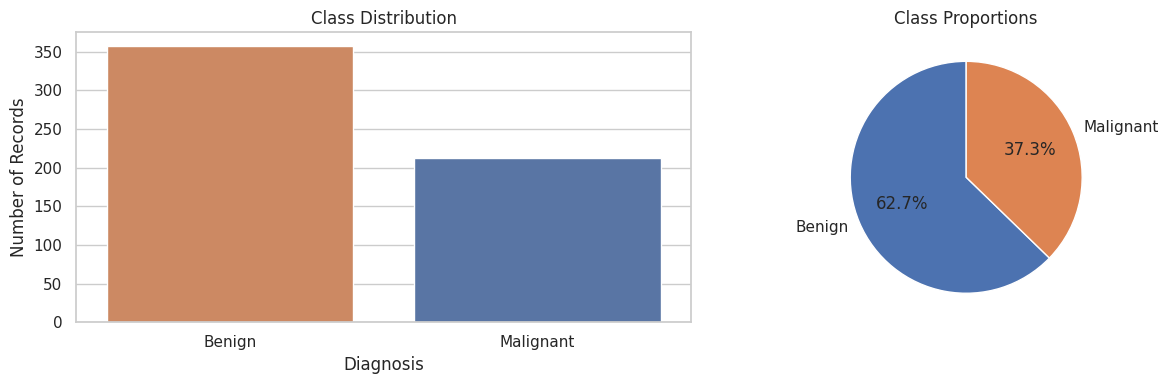

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    order=["Benign", "Malignant"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Class Distribution")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Number of Records")

class_counts = df["diagnosis"].value_counts()
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Class Proportions")

plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class proportions:")
display(
    y_train.map({0: "Malignant", 1: "Benign"})
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)

assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)

print("Train/test separation checks passed.")

Training records: 455
Testing records: 114

Training class proportions:


,Percentage
target,
Benign,62.64
Malignant,37.36


Train/test separation checks passed.


In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models defined:")
for name in models:
    print(" •", name)

Models defined:
 • Logistic Regression
 • Random Forest
 • Support Vector Machine


In [ ]:
cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro",
    "roc_auc": "roc_auc"
}

cv_results = []
fitted_cv_results = {}

for name, estimator in models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    fitted_cv_results[name] = scores

    row = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} Mean"] = values.mean()
        row[f"{metric.upper()} Std"] = values.std()

    cv_results.append(row)

cv_table = pd.DataFrame(cv_results)
cv_table = cv_table.sort_values(
    "ROC_AUC Mean",
    ascending=False
).reset_index(drop=True)

print("\nCROSS-VALIDATION RESULTS")
display(cv_table.round(4))

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Support Vector Machine...

CROSS-VALIDATION RESULTS


,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std
0,Logistic Regression,0.9780,0.0098,0.9782,0.0099,0.9753,0.0126,0.9764,0.0106,0.9959,0.0050
1,Support Vector Machine,0.9692,0.0146,0.9688,0.0134,0.9659,0.0189,0.9669,0.0160,0.9956,0.0048
2,Random Forest,0.9648,0.0176,0.9628,0.0202,0.9636,0.0185,0.9625,0.0185,0.9904,0.0072


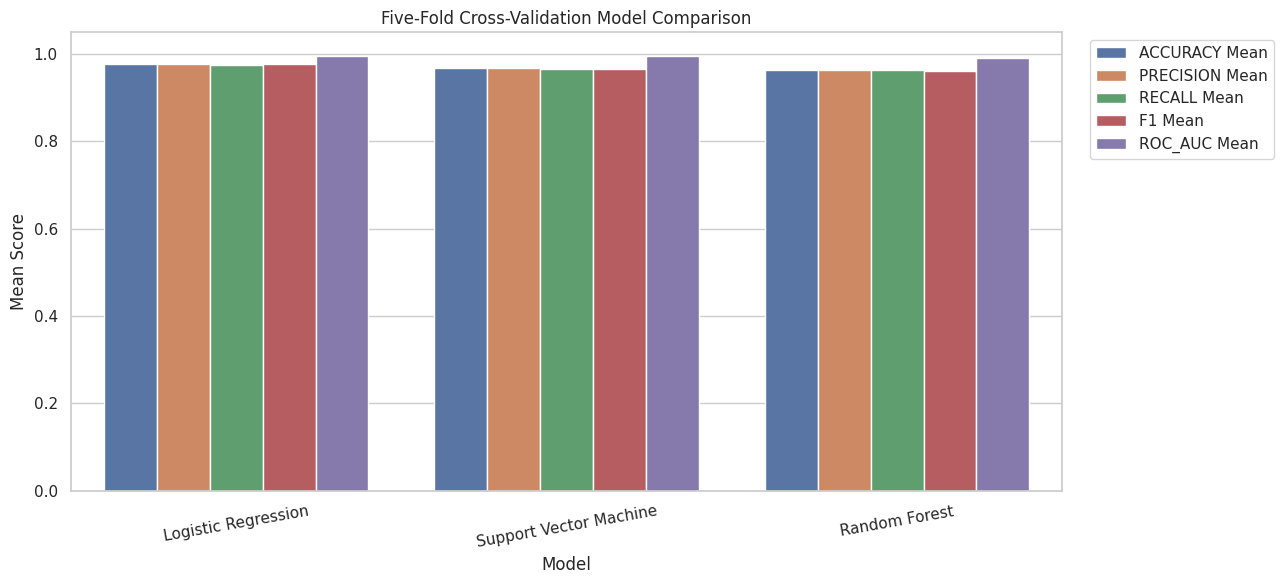

In [ ]:
plot_data = cv_table.melt(
    id_vars="Model",
    value_vars=[
        "ACCURACY Mean",
        "PRECISION Mean",
        "RECALL Mean",
        "F1 Mean",
        "ROC_AUC Mean"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)
plt.ylim(0, 1.05)
plt.title("Five-Fold Cross-Validation Model Comparison")
plt.ylabel("Mean Score")
plt.xticks(rotation=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = cv_table.iloc[0]["Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Recall (macro)": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "F1-score (macro)": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

print("SELECTED MODEL:", best_model_name)
print("\nHELD-OUT TEST RESULTS")

for metric, value in test_metrics.items():
    print(f"{metric:22s}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

SELECTED MODEL: Logistic Regression

HELD-OUT TEST RESULTS
Accuracy              : 0.9825
Precision (macro)     : 0.9812
Recall (macro)        : 0.9812
F1-score (macro)      : 0.9812
ROC-AUC               : 0.9954

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



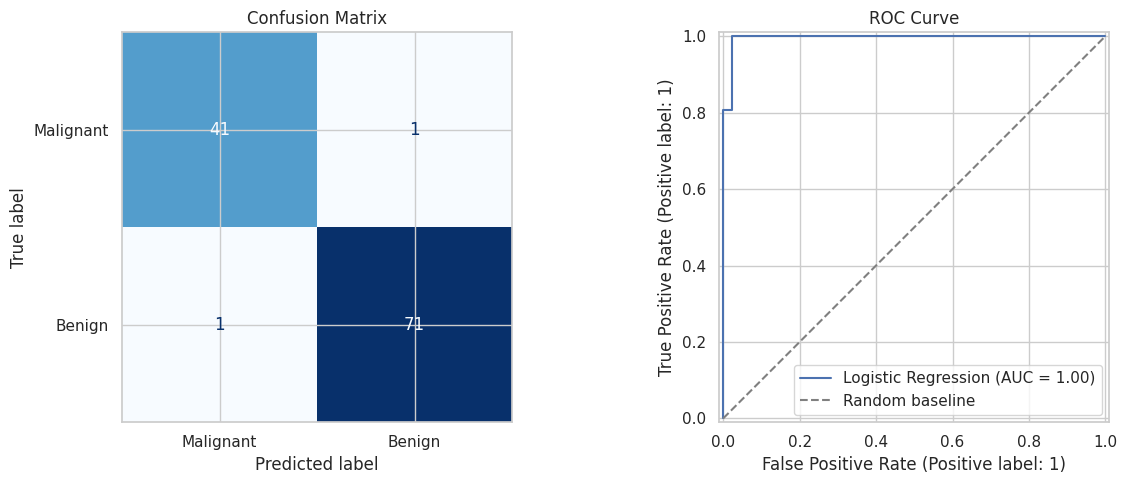

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_probability,
    name=best_model_name,
    ax=axes[1]
)
axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random baseline"
)
axes[1].set_title("ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

TOP 15 FEATURES BY PERMUTATION IMPORTANCE


,Feature,Importance,Std
24,worst smoothness,0.00354,0.00172
13,area error,0.00341,0.00337
10,radius error,0.00337,0.00242
21,worst texture,0.00337,0.00303
27,worst concave points,0.00321,0.00254
23,worst area,0.00317,0.00285
20,worst radius,0.00304,0.00313
7,mean concave points,0.00212,0.00212
22,worst perimeter,0.00205,0.00217
26,worst concavity,0.00162,0.00182


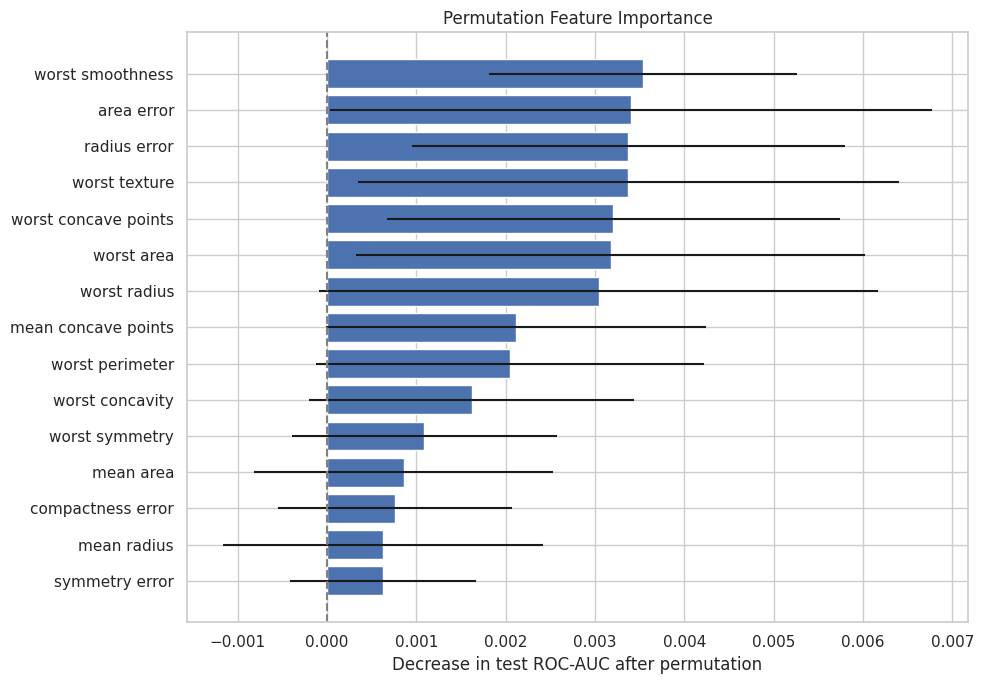

In [ ]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print("TOP 15 FEATURES BY PERMUTATION IMPORTANCE")
display(importance_df.head(15).round(5))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)
plt.axvline(0, linestyle="--", color="gray")
plt.xlabel("Decrease in test ROC-AUC after permutation")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
sample_index = 0
sample = X_test.iloc[[sample_index]]
actual = int(y_test.iloc[sample_index])

predicted = int(best_model.predict(sample)[0])
probabilities = best_model.predict_proba(sample)[0]

print("PREDICTION RESULT")
print("=" * 40)
print("Predicted class:", CLASS_NAMES[predicted])
print("Actual class:   ", CLASS_NAMES[actual])
print("\nPredicted class probabilities:")

for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_name:12s}: {probabilities[class_id]:.2%}")

print("\nFirst 10 input features:")
display(sample.iloc[:, :10].T.rename(columns={sample.index[0]: "Value"}))

PREDICTION RESULT
Predicted class: Malignant
Actual class:    Malignant

Predicted class probabilities:
Malignant   : 100.00%
Benign      : 0.00%

First 10 input features:


,Value
mean radius,19.55000
mean texture,28.77000
mean perimeter,133.60000
mean area,1207.00000
mean smoothness,0.09260
mean compactness,0.20630
mean concavity,0.17840
mean concave points,0.11440
mean symmetry,0.18930
mean fractal dimension,0.06232


In [ ]:
def predict_record(input_data):
    """
    Predict the class of a single record.

    input_data must be a pandas Series or a dictionary
    containing all 30 required feature names.
    """
    if isinstance(input_data, dict):
        record = pd.DataFrame([input_data])
    elif isinstance(input_data, pd.Series):
        record = input_data.to_frame().T
    else:
        raise TypeError("Pass a pandas Series or dictionary.")

    missing = set(FEATURE_NAMES) - set(record.columns)
    extra = set(record.columns) - set(FEATURE_NAMES)

    if missing or extra:
        raise ValueError(
            f"Missing features: {sorted(missing)}; "
            f"unexpected features: {sorted(extra)}"
        )

    record = record[FEATURE_NAMES].apply(
        pd.to_numeric, errors="raise"
    )

    if not np.isfinite(record.to_numpy(dtype=float)).all():
        raise ValueError("All feature values must be finite numbers.")

    predicted_class = int(best_model.predict(record)[0])
    class_probabilities = best_model.predict_proba(record)[0]

    return {
        "predicted_class": CLASS_NAMES[predicted_class],
        "probabilities": {
            CLASS_NAMES[i]: float(class_probabilities[i])
            for i in range(len(CLASS_NAMES))
        }
    }


# Example using a held-out record:
result = predict_record(X_test.iloc[0].to_dict())
print(result)

{'predicted_class': 'Malignant', 'probabilities': {'Malignant': 0.9999999411175814, 'Benign': 5.8882418607058566e-08}}


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/ai_ml_laboratory")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "best_model.joblib"
metrics_path = OUTPUT_DIR / "test_metrics.csv"
comparison_path = OUTPUT_DIR / "model_comparison.csv"
importance_path = OUTPUT_DIR / "feature_importance.csv"
predictions_path = OUTPUT_DIR / "test_predictions.csv"

# Save model and its expected feature schema together.
joblib.dump({
    "model": best_model,
    "model_name": best_model_name,
    "feature_names": FEATURE_NAMES,
    "class_names": CLASS_NAMES
}, model_path)

pd.DataFrame(
    list(test_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(metrics_path, index=False)

cv_table.to_csv(comparison_path, index=False)
importance_df.to_csv(importance_path, index=False)

prediction_report = X_test.copy()
prediction_report["Actual"] = y_test
prediction_report["Predicted"] = y_pred
prediction_report["Actual_Label"] = [
    CLASS_NAMES[int(value)] for value in y_test
]
prediction_report["Predicted_Label"] = [
    CLASS_NAMES[int(value)] for value in y_pred
]
prediction_report["Probability_Benign"] = y_probability

prediction_report.to_csv(predictions_path, index=False)

print("FILES EXPORTED SUCCESSFULLY")
for path in OUTPUT_DIR.iterdir():
    print(f"{path.name:28s} {path.stat().st_size:,} bytes")

FILES EXPORTED SUCCESSFULLY
model_comparison.csv         778 bytes
best_model.joblib            3,729 bytes
feature_importance.csv       1,825 bytes
test_predictions.csv         29,085 bytes
test_metrics.csv             175 bytes


In [ ]:
from google.colab import files

files.download(str(comparison_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Dataset and split checks
assert X.shape == (569, 30)
assert len(X_train) + len(X_test) == len(X)
assert len(y_pred) == len(y_test)

# Model evaluation checks
assert all(np.isfinite(v) for v in test_metrics.values())
assert 0 <= test_metrics["Accuracy"] <= 1
assert 0 <= test_metrics["ROC-AUC"] <= 1

# Prediction probability checks
assert np.all(np.isfinite(y_probability))
assert np.all((y_probability >= 0) & (y_probability <= 1))

probability_matrix = best_model.predict_proba(X_test)
assert np.allclose(probability_matrix.sum(axis=1), 1.0)
assert set(np.unique(y_pred)).issubset({0, 1})

# Feature importance checks
assert len(importance_df) == len(FEATURE_NAMES)
assert set(importance_df["Feature"]) == set(FEATURE_NAMES)

# File export checks
for path in [
    model_path,
    metrics_path,
    comparison_path,
    importance_path,
    predictions_path
]:
    assert path.exists() and path.stat().st_size > 0, (
        f"Missing or empty output: {path}"
    )

print("ALL VALIDATION TESTS PASSED")
print("Dataset checks: PASS")
print("Model metrics checks: PASS")
print("Prediction probability checks: PASS")
print("Feature importance checks: PASS")
print("File export checks: PASS")

ALL VALIDATION TESTS PASSED
Dataset checks: PASS
Model metrics checks: PASS
Prediction probability checks: PASS
Feature importance checks: PASS
File export checks: PASS
